# Level 2 - Task 1: Logistic Regression for Binary Classification
**Codveda ML Internship**

**Goal:** predict whether a telecom customer will **churn** (leave) - a yes/no outcome.

**Dataset:** Codveda's churn data. `churn_train.csv` (2,666 customers) is used for training and `churn_test.csv` (667 customers) as the untouched test set, exactly as the dataset was split.

**Steps:** 1) load and preprocess, 2) train, 3) interpret coefficients and odds ratios, 4) evaluate with accuracy, precision, recall and the ROC curve.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

DATA_DIR = "../data"  # NB
train = pd.read_csv(f"{DATA_DIR}/churn_train.csv")
test = pd.read_csv(f"{DATA_DIR}/churn_test.csv")
print("Train:", train.shape, "| Test:", test.shape)
print("Missing values:", int(train.isna().sum().sum()), "| Duplicates:", int(train.duplicated().sum()))
print("Churn rate (train): %.1f%%" % (train["Churn"].mean() * 100))
print(train.head(3).T.head(8))

Train: (2666, 20) | Test: (667, 20)
Missing values: 0 | Duplicates: 0
Churn rate (train): 14.6%
                           0      1      2
State                     KS     OH     NJ
Account length           128    107    137
Area code                415    415    415
International plan        No     No     No
Voice mail plan          Yes    Yes     No
Number vmail messages     25     26      0
Total day minutes      265.1  161.6  243.4
Total day calls          110    123    114


## Step 1: Preprocess
**What this means:** The data is clean (no missing values). Only about 1 in 7 customers churns, so the classes are **imbalanced**, which matters when reading accuracy later. We make three decisions:
- Drop `State` (51 categories, few customers each, would clutter the coefficient table).
- Drop the four `Total ... charge` columns: each is just minutes multiplied by a fixed rate, so it duplicates the minutes column. Keeping both makes coefficients unreliable (multicollinearity).
- Treat `Area code` as a category (it is a label, not a quantity), one-hot encode the yes/no plans, and scale the numbers.

In [2]:
drop_cols = ["State", "Total day charge", "Total eve charge", "Total night charge", "Total intl charge"]
y_train = train["Churn"].astype(int); y_test = test["Churn"].astype(int)
X_train = train.drop(columns=drop_cols + ["Churn"]); X_test = test.drop(columns=drop_cols + ["Churn"])
X_train["Area code"] = X_train["Area code"].astype(str); X_test["Area code"] = X_test["Area code"].astype(str)

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()
pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols)])
Xtr = pre.fit_transform(X_train)   # fit on TRAIN only
Xte = pre.transform(X_test)
feature_names = pre.get_feature_names_out()
print("Features:", Xtr.shape[1], "| Categorical:", cat_cols)

Features: 16 | Categorical: ['Area code', 'International plan', 'Voice mail plan']


## Step 2: Train the model

In [3]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(Xtr, y_train)
print("Trained. Intercept:", round(model.intercept_[0], 3))

Trained. Intercept: -2.106


## Step 3: Interpret coefficients and odds ratios

               feature  coefficient  odds_ratio
International plan_Yes        2.044       7.725
   Voice mail plan_Yes       -1.416       0.243
     Total day minutes        0.676       1.966
Customer service calls        0.659       1.932
      Total intl calls       -0.291       0.748
     Total eve minutes        0.284       1.329
    Total intl minutes        0.277       1.320
 Number vmail messages        0.253       1.287
   Total night minutes        0.140       1.150
       Total day calls        0.056       1.058


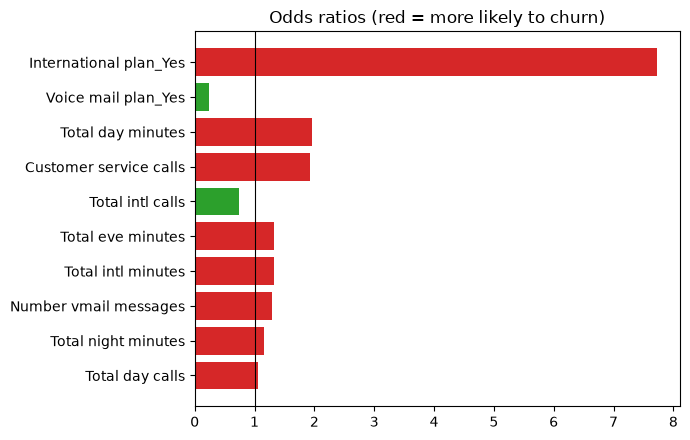

In [4]:
coef = pd.DataFrame({"feature": [f.split("__")[1] for f in feature_names], "coefficient": model.coef_[0]})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(coef.round(3).head(10).to_string(index=False))

top = coef.head(10)[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["odds_ratio"], color=["tab:red" if v > 1 else "tab:green" for v in top["odds_ratio"]])
plt.axvline(1, color="black", linewidth=0.8)
plt.title("Odds ratios (red = more likely to churn)")
plt.tight_layout(); plt.show()

**What this means:** A **coefficient** is the change in the log-odds of churning. The **odds ratio** (`exp(coefficient)`) is easier to read: above 1 raises the odds of churn, below 1 lowers them, and 1 means no effect.
- For numeric columns (scaled), the odds ratio is for a **+1 standard deviation** increase. For example, `Customer service calls` above 1 means more calls to support goes with more churn.
- For `International plan` and `Voice mail plan` (yes/no), it is the odds for customers *with* the plan compared with those without.
- Odds ratios describe association, not proof of cause.

## Step 4: Evaluate on the test set

Accuracy : 0.853
Precision: 0.459
Recall   : 0.179
ROC AUC  : 0.825
Baseline accuracy (always predict 'no churn'): 0.858


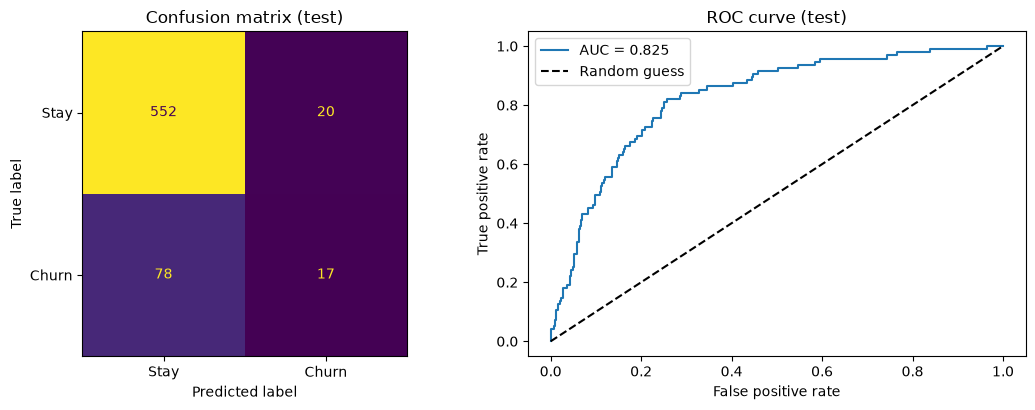

In [5]:
pred = model.predict(Xte)
proba = model.predict_proba(Xte)[:, 1]
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("ROC AUC  :", round(roc_auc_score(y_test, proba), 3))
print("Baseline accuracy (always predict 'no churn'):", round(1 - y_test.mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label="AUC = %.3f" % roc_auc_score(y_test, proba))
ax[1].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)")
ax[1].legend(); plt.tight_layout(); plt.show()

**What this means:**
- **Accuracy** is the share of correct predictions, but it is misleading here: always guessing "no churn" already scores about 86%.
- **Precision:** of the customers we flag as churners, how many really churn.
- **Recall:** of the customers who really churn, how many we catch. For churn, missing a leaver is usually costly, so recall matters.
- **ROC curve / AUC:** how well the model ranks churners above stayers across all thresholds (0.5 is a coin flip, 1.0 is perfect).

## Conclusion
- Logistic regression gives an interpretable churn model, with the strongest drivers visible in the odds ratios.
- Accuracy looks fine mainly because of class imbalance; recall is much weaker, so the model misses many churners.
- Next steps: try `class_weight="balanced"`, lower the decision threshold, or compare tree-based models.